
#Text Mining and Analysis of Amazon Food  Reviews





  
- Nusrat Jahan Chowdhury (2022-2-60-029)  
  


# Dataset:https://drive.google.com/file/d/17YYfWpmL_dOBv16gi_5AA-cEyANQNJhX/view?usp=sharing


#  Install and Import All Libraries


In [1]:
!pip install gdown nltk scikit-learn mlxtend wordcloud

In [3]:



import gdown
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, classification_report, confusion_matrix, accuracy_score
from sklearn.preprocessing import LabelEncoder
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder
from wordcloud import WordCloud
from collections import Counter
from itertools import chain
import warnings
warnings.filterwarnings('ignore')

import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords, wordnet
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.util import ngrams
from nltk.collocations import BigramCollocationFinder, BigramAssocMeasures
from nltk.sentiment.vader import SentimentIntensityAnalyzer

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import (silhouette_score, accuracy_score,
                             classification_report, confusion_matrix)
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules
from wordcloud import WordCloud
from IPython.display import display, HTML

nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)
nltk.download('averaged_perceptron_tagger', quiet=True)
nltk.download('averaged_perceptron_tagger_eng', quiet=True)
nltk.download('vader_lexicon', quiet=True)



print(' All libraries imported!')

 All libraries imported!


###  Downloading amazon_reviews_3000.csv from Google Drive

In [4]:


import gdown

file_id = '17YYfWpmL_dOBv16gi_5AA-cEyANQNJhX'
gdown.download(id=file_id, output='amazon_reviews_3000.csv', quiet=False)
print('Download complete!')

Downloading...
From: https://drive.google.com/uc?id=17YYfWpmL_dOBv16gi_5AA-cEyANQNJhX
To: /content/amazon_reviews_3000.csv
100%|██████████| 1.46M/1.46M [00:00<00:00, 151MB/s]

Download complete!


### Loading Dataset

In [5]:

df = pd.read_csv('amazon_reviews_3000.csv')
df = df.sample(frac=1, random_state=42).reset_index(drop=True)


print('Dataset shape:', df.shape)
print('Columns:', df.columns.tolist())
df.head(3)

Dataset shape: (3000, 3)
Columns: ['review', 'rating', 'sentiment']


,review,rating,sentiment
0,Amazon has made a great service introduce me t...,3,neutral
1,Our pit mix loves to chew especially when bore...,3,neutral
2,"As natural products go, sometimes they are goo...",3,neutral


### Class Distribution

📊 Class Distribution:
sentiment
neutral     1000
negative    1000
positive    1000
Name: count, dtype: int64


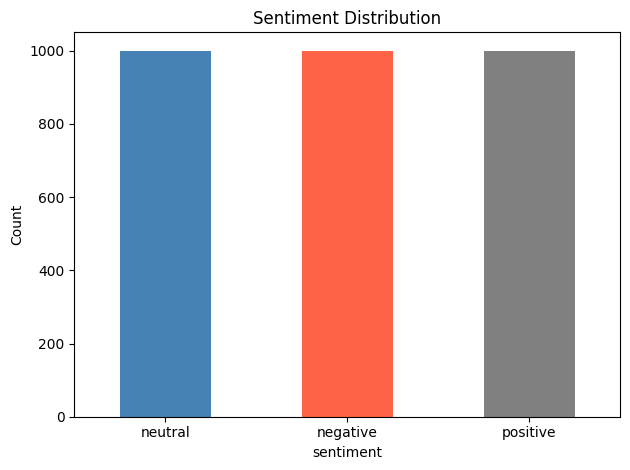

In [6]:

print('📊 Class Distribution:')
print(df['sentiment'].value_counts())

df['sentiment'].value_counts().plot(
    kind='bar',
    color=['steelblue', 'tomato', 'gray'],
    title='Sentiment Distribution',
    rot=0)
plt.ylabel('Count')
plt.tight_layout()
plt.show()

###Document Length Statistics

📊 Document Length Statistics (number of words):
  Min    : 11
  Max    : 864
  Mean   : 86.9
  Median : 62.0


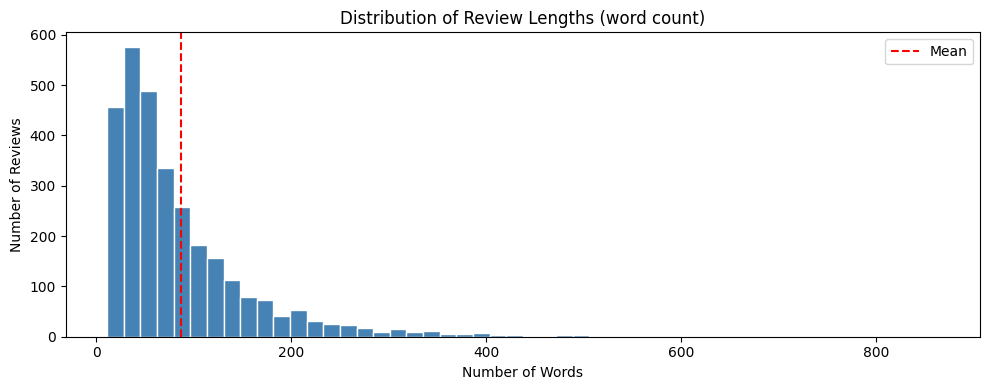

In [7]:

df['word_count'] = df['review'].apply(lambda x: len(str(x).split()))

print('📊 Document Length Statistics (number of words):')
print(f"  Min    : {df['word_count'].min()}")
print(f"  Max    : {df['word_count'].max()}")
print(f"  Mean   : {df['word_count'].mean():.1f}")
print(f"  Median : {df['word_count'].median()}")

plt.figure(figsize=(10, 4))
plt.hist(df['word_count'], bins=50, color='steelblue', edgecolor='white')
plt.title('Distribution of Review Lengths (word count)')
plt.xlabel('Number of Words')
plt.ylabel('Number of Reviews')
plt.axvline(df['word_count'].mean(), color='red', linestyle='--', label='Mean')
plt.legend()
plt.tight_layout()
plt.show()

#  Raw Sample Documents

In [8]:

print(' 3 Raw Sample Reviews (truncated to 300 chars):')
print('='*70)
for i, row in df.sample(3, random_state=1).iterrows():
    print(f"[{row['sentiment'].upper()}] {str(row['review'])[:300]}...")
    print('-'*70)

 3 Raw Sample Reviews (truncated to 300 chars):
[NEGATIVE] I feed my cats Friskies canned cat food a lot (mixed in with their Purina Cat Chow) and they enjoy it, but for some reason, this "Mixed Grill" is their least favorite flavor....
----------------------------------------------------------------------
[NEGATIVE] My wife and I ate the recommended serving (2 oz dried). It was delicious, and we felt full afterwards. Later that night, neither of us slept well because we were so hungry. I don't know if this is related, but we both had heart palpitations that night.<br /><br />We both woke up feeling starved. I u...
----------------------------------------------------------------------
[NEUTRAL] tasty, sweet, smooth, savory, refreshing.  a good, middle of the road, coffee beverage.  There was nothing I didn't like about it, yet nothing that really stood out.  Would I buy it again? Maybe....
----------------------------------------------------------------------



# TASK 2: Text Normalization and Tokenization


In [9]:
import html

def normalize_text(text):
    text = str(text)
    text = html.unescape(text)                    # 1. Decode HTML entities
    text = text.lower()                           # 2. Lowercase
    text = re.sub(r'<.*?>',          ' ', text)   # 3. Remove HTML tags
    text = re.sub(r'http\S+|www\S+', ' ', text)   # 4. Remove URLs
    text = re.sub(r'\S+@\S+',        ' ', text)   # 5. Remove emails
    text = re.sub(r'\d+',            ' ', text)   # 6. Remove numbers
    text = re.sub(r'[^a-z\s]',       ' ', text)   # 7. Remove punctuation
    text = re.sub(r'\s+',            ' ', text).strip()  # 8. Extra spaces
    tokens = word_tokenize(text)                  # 9. Tokenize
    return tokens

df['tokens'] = df['review'].apply(normalize_text)

sample_idx = 0
print('BEFORE (raw):')
print(str(df['review'][sample_idx])[:400])
print('\nAFTER (tokens):')
print(df['tokens'][sample_idx][:30], '...')

BEFORE (raw):
Amazon has made a great service introduce me to Kitchens of India products. These spicy Indian meals makes lunches during work a very simple endeavor. However, after trying several varieties I did not find the spinach dish as good as the other ones.<br /><br />Don't get me wrong. It still tastes Ok, and it's still easy to prepare/serve. However the general green soupy substance is not as delicious

AFTER (tokens):
['amazon', 'has', 'made', 'a', 'great', 'service', 'introduce', 'me', 'to', 'kitchens', 'of', 'india', 'products', 'these', 'spicy', 'indian', 'meals', 'makes', 'lunches', 'during', 'work', 'a', 'very', 'simple', 'endeavor', 'however', 'after', 'trying', 'several', 'varieties'] ...




# TASK 3: Stopword Removal



In [10]:

stop_words = set(stopwords.words('english'))

# Domain-specific stopwords for Amazon Food Reviews
domain_stopwords = {
    'product', 'food', 'buy', 'one', 'would', 'also',
    'get', 'could', 'order', 'amazon', 'item', 'use'
}
stop_words.update(domain_stopwords)

print(f'Total stopwords: {len(stop_words)} '
      f'(including {len(domain_stopwords)} domain-specific)')

# Top 20 BEFORE
all_tokens_before = [t for tokens in df['tokens'] for t in tokens]
top20_before      = Counter(all_tokens_before).most_common(20)
print('\nTop 20 tokens BEFORE stopword removal:')
print([w for w, c in top20_before])

# Remove stopwords
df['tokens_clean'] = df['tokens'].apply(
    lambda toks: [t for t in toks if t not in stop_words and len(t) > 2]
)

# Top 20 AFTER
all_tokens_after = [t for tokens in df['tokens_clean'] for t in tokens]
top20_after      = Counter(all_tokens_after).most_common(20)
print('\nTop 20 tokens AFTER stopword removal:')
print([w for w, c in top20_after])

Total stopwords: 210 (including 12 domain-specific)

Top 20 tokens BEFORE stopword removal:
['the', 'i', 'a', 'and', 'it', 'to', 'of', 'is', 'this', 'in', 'for', 'that', 'not', 'but', 'my', 'was', 'you', 't', 'with', 'have']

Top 20 tokens AFTER stopword removal:
['like', 'taste', 'good', 'coffee', 'flavor', 'tea', 'great', 'really', 'much', 'love', 'little', 'even', 'time', 'better', 'price', 'try', 'make', 'dog', 'tried', 'box']



# TASK 4: Stemming and Lemmatization


In [11]:
stemmer    = PorterStemmer()
lemmatizer = WordNetLemmatizer()

def get_wordnet_pos(tag):
    return {
        'J': wordnet.ADJ,
        'V': wordnet.VERB,
        'N': wordnet.NOUN,
        'R': wordnet.ADV
    }.get(tag[0].upper(), wordnet.NOUN)

def lemmatize_tokens(tokens):
    if not tokens:
        return []
    pos_tags = nltk.pos_tag(tokens)
    return [
        lemmatizer.lemmatize(word, pos=get_wordnet_pos(tag))
        for word, tag in pos_tags
    ]

# Apply BOTH to same cleaned token list
df['tokens_stem']  = df['tokens_clean'].apply(
    lambda toks: [stemmer.stem(t) for t in toks]   # Porter stemmer
)
df['tokens_lemma'] = df['tokens_clean'].apply(lemmatize_tokens)  # WordNet lemmatizer

# ── Build comparison table from tokens_clean vocabulary ───
all_tokens = list(chain.from_iterable(df['tokens_clean']))
top_words  = [word for word, _ in Counter(all_tokens).most_common(100)]

def transforms_under_any_pos(word):
    if stemmer.stem(word) != word:
        return True
    for pos in [wordnet.VERB, wordnet.NOUN, wordnet.ADJ, wordnet.ADV]:
        if lemmatizer.lemmatize(word, pos=pos) != word:
            return True
    return False

sample_words = []
for word in top_words:
    if len(sample_words) == 15:
        break
    if transforms_under_any_pos(word):
        sample_words.append(word)

stems  = [stemmer.stem(w) for w in sample_words]
lemmas = [lemmatizer.lemmatize(w) for w in sample_words]

comparison_df = pd.DataFrame({
    'Original'     : sample_words,
    'Porter Stem'  : stems,
    'WordNet Lemma': lemmas,
})

display(HTML(
    comparison_df.style
    .set_caption("Stemming vs Lemmatization — 15 words from Amazon dataset")
    .set_table_styles([
        {'selector': 'caption',
         'props': 'font-family:monospace;font-size:13px;font-weight:600;'
                  'text-align:left;padding-bottom:8px;color:#111;'},
        {'selector': 'thead th',
         'props': 'font-family:monospace;font-size:12px;font-weight:600;'
                  'text-align:right;padding:6px 20px;'
                  'border-bottom:1px solid #ccc;color:#555;'},
        {'selector': 'tbody td',
         'props': 'font-family:monospace;font-size:13px;'
                  'text-align:right;padding:4px 20px;color:#111;'},
        {'selector': 'tbody tr:nth-child(even)',
         'props': 'background-color:#f7f7f7;'},
        {'selector': 'tbody tr:hover',
         'props': 'background-color:#eef4ff;'},
        {'selector': '',
         'props': 'border-collapse:collapse;width:auto;'},
    ])
    .hide(axis='index')
    .to_html()
))



Original,Porter Stem,WordNet Lemma
taste,tast,taste
coffee,coffe,coffee
really,realli,really
little,littl,little
better,better,better
try,tri,try
tried,tri,tried
chocolate,chocol,chocolate
made,made,made
bought,bought,bought


### Choosing lemmatization for downstream tasks

In [12]:

print('\n Applying lemmatization to full dataset...')
df['final_tokens'] = df['tokens_lemma']

print('Sample — first review, first 20 tokens:')
print(df['final_tokens'].iloc[0][:20])


 Applying lemmatization to full dataset...
Sample — first review, first 20 tokens:
['make', 'great', 'service', 'introduce', 'kitchens', 'india', 'product', 'spicy', 'indian', 'meal', 'make', 'lunch', 'work', 'simple', 'endeavor', 'however', 'try', 'several', 'variety', 'find']


### Saving Preprocessed Dataset

In [13]:

preprocessed_df = pd.DataFrame({
    'review_id'        : range(1, len(df) + 1),
    'original_review'  : df['review'],
    'cleaned_review'   : df['final_tokens'].apply(lambda x: ' '.join(x)),
    'sentiment'        : df['sentiment'],
    'word_count_before': df['word_count'],
    'word_count_after' : df['final_tokens'].apply(len),
})

preprocessed_df.to_csv('Amazon_Preprocessed_Dataset.csv', index=False, encoding='utf-8')
print(' Preprocessed dataset saved!')
print(f'   Shape: {preprocessed_df.shape[0]:,} rows × {preprocessed_df.shape[1]} columns')
display(preprocessed_df.head(5))

from google.colab import files
files.download('Amazon_Preprocessed_Dataset.csv')

 Preprocessed dataset saved!
   Shape: 3,000 rows × 6 columns


,review_id,original_review,cleaned_review,sentiment,word_count_before,word_count_after
0,1,Amazon has made a great service introduce me t...,make great service introduce kitchens india pr...,neutral,143,68
1,2,Our pit mix loves to chew especially when bore...,pit mix love chew especially bore buy think ch...,neutral,80,39
2,3,"As natural products go, sometimes they are goo...",natural product sometimes good time good zoe g...,neutral,56,29
3,4,"Espresso was fine. However, the photo is misle...",espresso fine however photo mislead disappoint...,negative,52,25
4,5,"I saw the price on Amazon, and I jumped at it!...",saw price jump great deal compare others find ...,positive,39,20


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


# TASK 5: Frequency Analysis


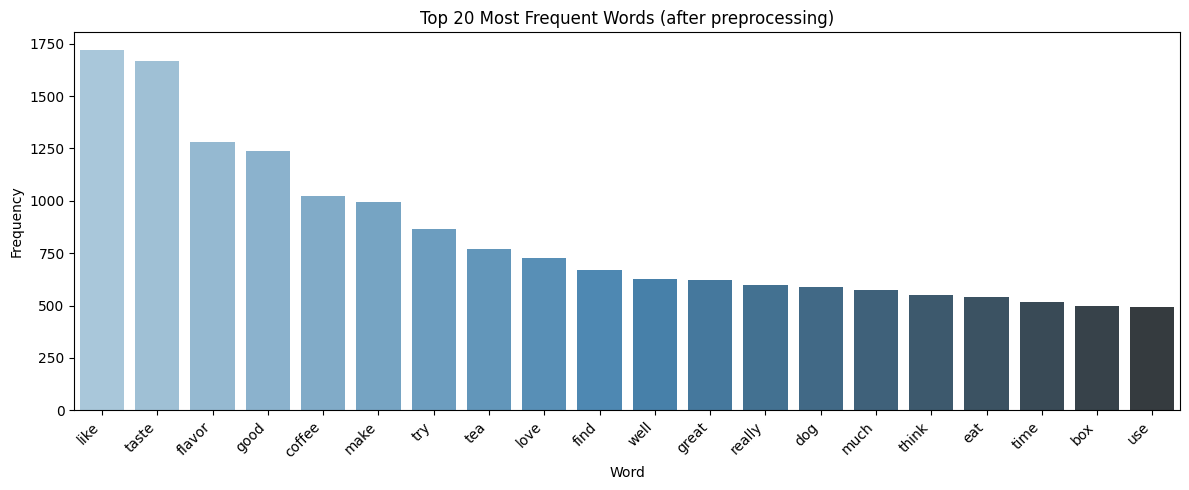

Seed Word Counts by Sentiment Class:
Word            Total   Positive   Negative    Neutral
--------------------------------------------------------
taste            1665        424        600        641
flavor           1279        370        373        536
fresh             139         50         40         49
quality           196         57         65         74
price             472        163        146        163


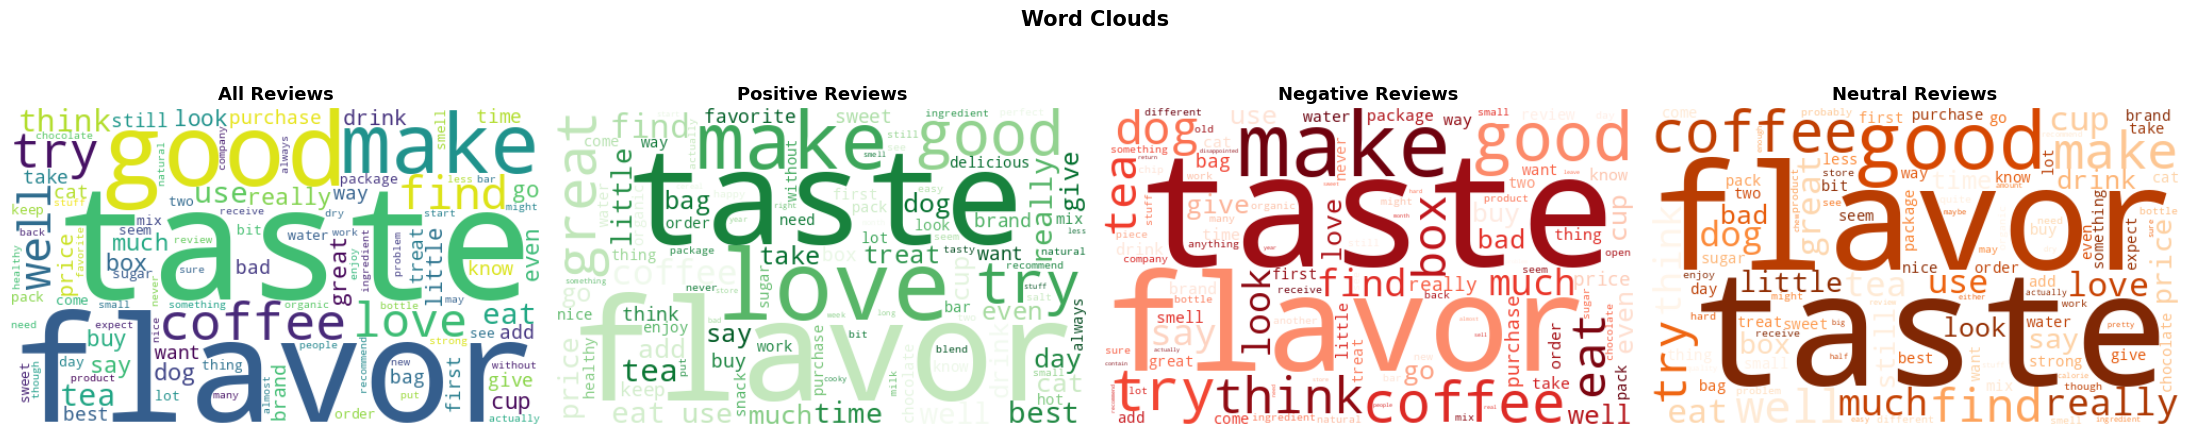

In [14]:
all_tokens = [t for tokens in df['final_tokens'] for t in tokens]
freq_dist  = Counter(all_tokens)

# Top 20 bar chart
top20        = freq_dist.most_common(20)
words_top20  = [w for w, c in top20]
counts_top20 = [c for w, c in top20]

plt.figure(figsize=(12, 5))
sns.barplot(x=words_top20, y=counts_top20, palette='Blues_d')
plt.title('Top 20 Most Frequent Words (after preprocessing)')
plt.xlabel('Word')
plt.ylabel('Frequency')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Seed words — food domain
seed_words = ['taste', 'flavor', 'fresh', 'quality', 'price']

print('Seed Word Counts by Sentiment Class:')
print(f"{'Word':<12} {'Total':>8} {'Positive':>10} {'Negative':>10} {'Neutral':>10}")
print('-' * 56)

for word in seed_words:
    total     = freq_dist[word]
    pos_count = sum(tokens.count(word) for tokens in df[df['sentiment']=='positive']['final_tokens'])
    neg_count = sum(tokens.count(word) for tokens in df[df['sentiment']=='negative']['final_tokens'])
    neu_count = sum(tokens.count(word) for tokens in df[df['sentiment']=='neutral']['final_tokens'])
    print(f"{word:<12} {total:>8} {pos_count:>10} {neg_count:>10} {neu_count:>10}")

# Word Clouds — 4 (all + 3 classes)
fig, axes = plt.subplots(1, 4, figsize=(22, 5))

def make_wordcloud(tokens_list, title, ax, colormap='Blues'):
    text = ' '.join([t for tokens in tokens_list for t in tokens])
    wc   = WordCloud(width=500, height=300, background_color='white',
                     colormap=colormap, max_words=100).generate(text)
    ax.imshow(wc, interpolation='bilinear')
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.axis('off')

make_wordcloud(df['final_tokens'],                              'All Reviews',      axes[0], 'viridis')
make_wordcloud(df[df['sentiment']=='positive']['final_tokens'], 'Positive Reviews', axes[1], 'Greens')
make_wordcloud(df[df['sentiment']=='negative']['final_tokens'], 'Negative Reviews', axes[2], 'Reds')
make_wordcloud(df[df['sentiment']=='neutral']['final_tokens'],  'Neutral Reviews',  axes[3], 'Oranges')

plt.suptitle('Word Clouds', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()


# TASK 6: Bigram and Trigram Analysis


In [15]:

all_bigrams  = [bg for tokens in df['final_tokens'] for bg in ngrams(tokens, 2)]
all_trigrams = [tg for tokens in df['final_tokens'] for tg in ngrams(tokens, 3)]

bigram_freq  = Counter(all_bigrams)
trigram_freq = Counter(all_trigrams)

top15_bigrams  = bigram_freq.most_common(15)
top15_trigrams = trigram_freq.most_common(15)

print('Top 15 Bigrams:')
for bg, count in top15_bigrams:
    print(f"  {' '.join(bg):<30} {count}")

print('\nTop 15 Trigrams:')
for tg, count in top15_trigrams:
    print(f"  {' '.join(tg):<40} {count}")




Top 15 Bigrams:
  taste like                     234
  grocery store                  105
  taste good                     95
  peanut butter                  85
  look like                      63
  year old                       63
  dark chocolate                 60
  green tea                      60
  gluten free                    59
  really like                    58
  cup coffee                     55
  dog love                       53
  tea bag                        52
  highly recommend               51
  taste great                    51

Top 15 Trigrams:
  local grocery store                      25
  taste nothing like                       12
  high fructose corn                       12
  fructose corn syrup                      12
  really want like                         11
  decide give try                          11
  taste like coffee                        9
  taste like cardboard                     9
  salt vinegar chip                        9
  taste exact

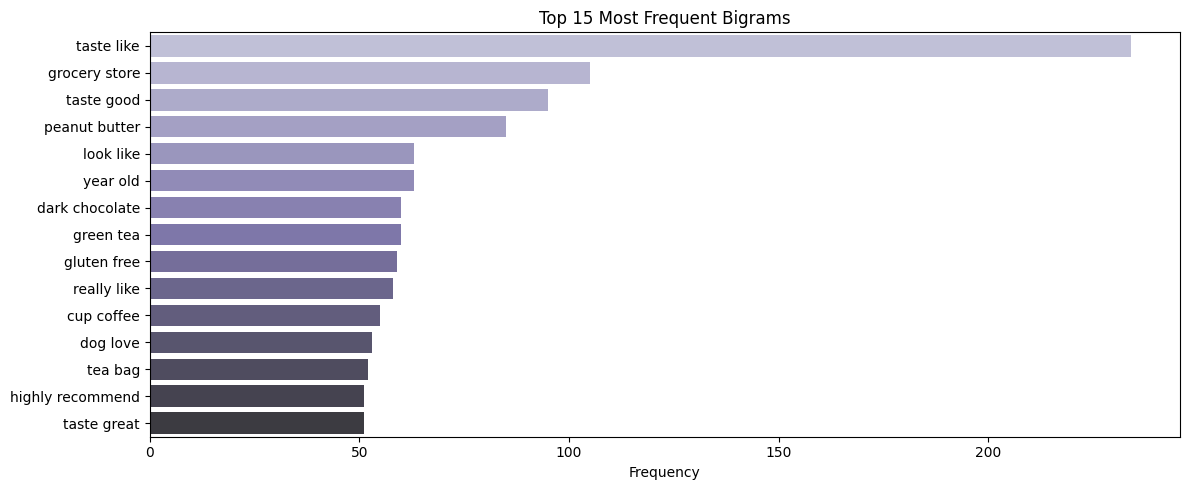

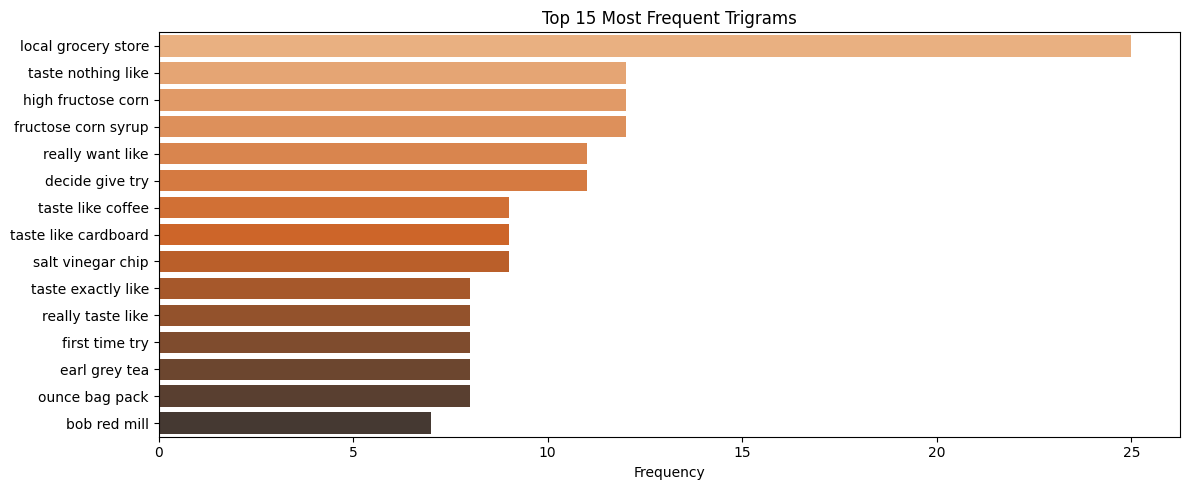

In [16]:
bg_labels = [' '.join(bg) for bg, _ in top15_bigrams]
bg_counts = [c for _, c in top15_bigrams]
plt.figure(figsize=(12, 5))
sns.barplot(x=bg_counts, y=bg_labels, palette='Purples_d')
plt.title('Top 15 Most Frequent Bigrams')
plt.xlabel('Frequency')
plt.tight_layout()
plt.show()

tg_labels = [' '.join(tg) for tg, _ in top15_trigrams]
tg_counts = [c for _, c in top15_trigrams]
plt.figure(figsize=(12, 5))
sns.barplot(x=tg_counts, y=tg_labels, palette='Oranges_d')
plt.title('Top 15 Most Frequent Trigrams')
plt.xlabel('Frequency')
plt.tight_layout()
plt.show()

In [17]:
finder = BigramCollocationFinder.from_documents(df['final_tokens'])
finder.apply_freq_filter(5)
bigram_measures = BigramAssocMeasures()

pmi_bigrams = finder.nbest(bigram_measures.pmi, 15)  # ← assign FIRST

print('Top 15 Bigrams by PMI (strong collocations):')
for bg in pmi_bigrams:
    score = finder.score_ngram(bigram_measures.pmi, bg[0], bg[1])
    print(f"  {' '.join(bg):<30} PMI: {score:.4f}")

Top 15 Bigrams by PMI (strong collocations):
  titanium dioxide               PMI: 14.2730
  fig newton                     PMI: 14.0506
  propylene glycol               PMI: 14.0506
  crown prince                   PMI: 14.0100
  kool aid                       PMI: 13.6881
  aloe vera                      PMI: 13.6356
  timely manner                  PMI: 13.6356
  wolfgang puck                  PMI: 13.5361
  gloria jean                    PMI: 13.3985
  lickety stik                   PMI: 13.3726
  wal mart                       PMI: 13.2730
  creme brulee                   PMI: 13.1575
  vita coco                      PMI: 13.0506
  jet fuel                       PMI: 12.6450
  buffalo wing                   PMI: 12.6101



# TASK 7: Word Co-occurrence Analysis


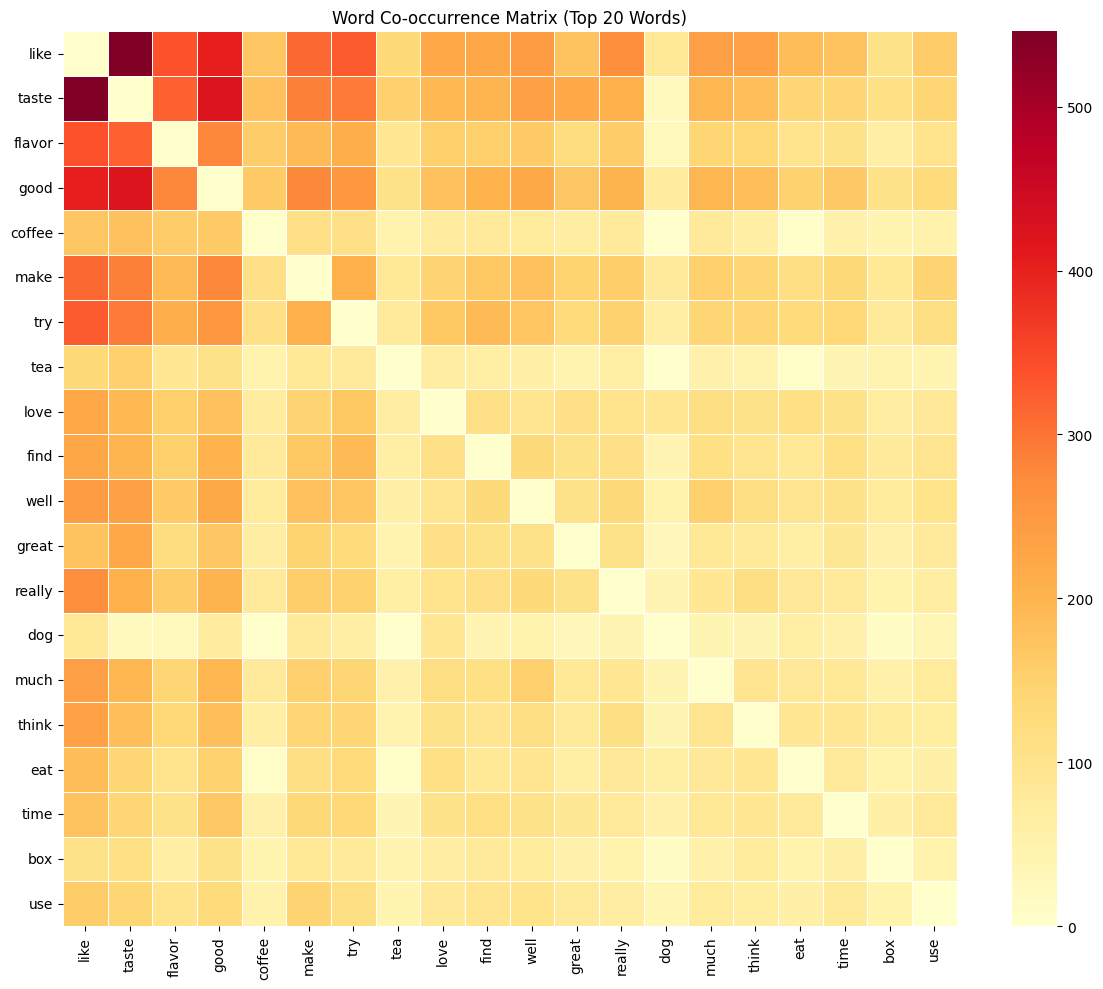

In [18]:

top20_words = [w for w, c in freq_dist.most_common(20)]

cooc_matrix = pd.DataFrame(
    np.zeros((20, 20), dtype=int),
    index=top20_words, columns=top20_words)

for tokens in df['final_tokens']:
    token_set  = set(tokens) & set(top20_words)
    token_list = list(token_set)
    for i in range(len(token_list)):
        for j in range(i+1, len(token_list)):
            w1, w2 = token_list[i], token_list[j]
            cooc_matrix.loc[w1, w2] += 1
            cooc_matrix.loc[w2, w1] += 1

plt.figure(figsize=(12, 10))
sns.heatmap(cooc_matrix, annot=False, cmap='YlOrRd', linewidths=0.5)
plt.title('Word Co-occurrence Matrix (Top 20 Words)')
plt.tight_layout()
plt.show()



In [19]:
print('\n Top 5 Strongest Co-occurring Word Pairs:')
pairs = []
for i in range(len(top20_words)):
    for j in range(i+1, len(top20_words)):
        w1, w2 = top20_words[i], top20_words[j]
        pairs.append((w1, w2, cooc_matrix.loc[w1, w2]))
pairs.sort(key=lambda x: x[2], reverse=True)
for w1, w2, count in pairs[:5]:
    print(f"  '{w1}' & '{w2}': {int(count)} documents")


 Top 5 Strongest Co-occurring Word Pairs:
  'like' & 'taste': 546 documents
  'taste' & 'good': 423 documents
  'like' & 'good': 401 documents
  'like' & 'flavor': 338 documents
  'like' & 'try': 328 documents



# TASK 8: Apriori Association-Rule Mining


In [20]:

top200_words = set([w for w, c in freq_dist.most_common(200)])

transactions = [
    list(set(tokens) & top200_words)
    for tokens in df['final_tokens']
]

te       = TransactionEncoder()
te_array = te.fit_transform(transactions)
trans_df = pd.DataFrame(te_array, columns=te.columns_)

print(f'Transaction matrix shape: {trans_df.shape}')

frequent_itemsets = apriori(trans_df, min_support=0.05, use_colnames=True)
print(f'Frequent itemsets found: {len(frequent_itemsets)}')

rules = association_rules(frequent_itemsets, metric='confidence', min_threshold=0.6)
rules = rules[rules['lift'] > 1]
rules_sorted = rules.sort_values('lift', ascending=False)

print(f'\nAssociation rules found: {len(rules_sorted)}')
print('\n Top 10 Rules by Lift:')
print(rules_sorted[['antecedents','consequents',
                     'support','confidence','lift']].head(10).to_string(index=False))

Transaction matrix shape: (3000, 200)
Frequent itemsets found: 184

Association rules found: 2

 Top 10 Rules by Lift:
    antecedents consequents  support  confidence     lift
   (taste, try)      (like) 0.063000    0.645051 1.778634
(taste, flavor)      (like) 0.066667    0.625000 1.723346



# TASK 9: Correlation Analysis from Data Chunks


4x4 Pearson Correlation Matrix between Chunks:
         Chunk 1  Chunk 2  Chunk 3  Chunk 4
Chunk 1   1.0000   0.9700   0.9715   0.9727
Chunk 2   0.9700   1.0000   0.9576   0.9666
Chunk 3   0.9715   0.9576   1.0000   0.9595
Chunk 4   0.9727   0.9666   0.9595   1.0000


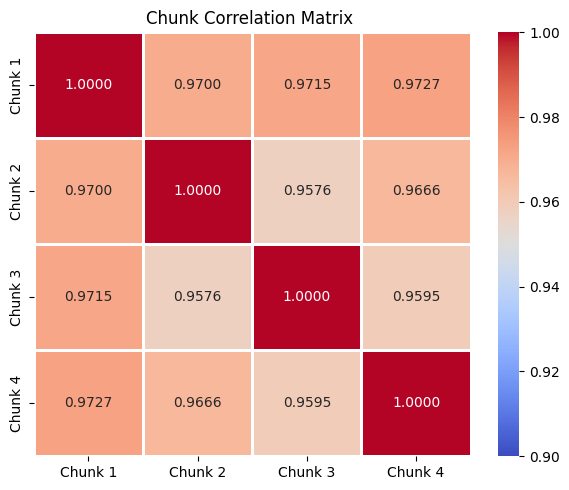

In [21]:
df_shuffled = df.sample(frac=1, random_state=42).reset_index(drop=True)
chunk_size  = len(df_shuffled) // 4
chunks      = [df_shuffled.iloc[i*chunk_size:(i+1)*chunk_size] for i in range(4)]

top30_words = [w for w, c in freq_dist.most_common(30)]

chunk_freqs = {}
for i, chunk in enumerate(chunks):
    chunk_tokens  = [t for tokens in chunk['final_tokens'] for t in tokens]
    chunk_counter = Counter(chunk_tokens)
    total         = sum(chunk_counter.values())
    chunk_freqs[f'Chunk {i+1}'] = [chunk_counter[w]/total for w in top30_words]

chunk_df    = pd.DataFrame(chunk_freqs, index=top30_words)
corr_matrix = chunk_df.corr()

print('4x4 Pearson Correlation Matrix between Chunks:')
print(corr_matrix.round(4))

plt.figure(figsize=(6, 5))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm',
            vmin=0.9, vmax=1.0, linewidths=1, fmt='.4f')
plt.title('Chunk Correlation Matrix ')
plt.tight_layout()
plt.show()


# TASK 10: TF-IDF Matrix


In [22]:

df['clean_text'] = df['final_tokens'].apply(lambda tokens: ' '.join(tokens))

tfidf        = TfidfVectorizer(max_features=2000, min_df=5)
tfidf_matrix = tfidf.fit_transform(df['clean_text'])

print(f'TF-IDF matrix shape: {tfidf_matrix.shape}')
print(f'  → {tfidf_matrix.shape[0]} documents × {tfidf_matrix.shape[1]} features')

feature_names = np.array(tfidf.get_feature_names_out())
tfidf_df      = pd.DataFrame(tfidf_matrix.toarray(), columns=feature_names)
tfidf_df['sentiment'] = df['sentiment'].values

for label in ['positive', 'negative', 'neutral']:
    mean_tfidf = tfidf_df[tfidf_df['sentiment']==label].drop('sentiment', axis=1).mean()
    top10      = mean_tfidf.nlargest(10)
    print(f'\nTop 10 TF-IDF words for {label.upper()} reviews:')
    print(top10.round(4).to_string())

TF-IDF matrix shape: (3000, 2000)
  → 3000 documents × 2000 features

Top 10 TF-IDF words for POSITIVE reviews:
love      0.0416
great     0.0411
taste     0.0327
good      0.0325
coffee    0.0321
like      0.0318
flavor    0.0293
tea       0.0289
make      0.0269
try       0.0247

Top 10 TF-IDF words for NEGATIVE reviews:
taste     0.0442
like      0.0392
coffee    0.0290
flavor    0.0287
good      0.0247
tea       0.0235
make      0.0235
box       0.0225
dog       0.0214
try       0.0214

Top 10 TF-IDF words for NEUTRAL reviews:
taste     0.0410
coffee    0.0409
flavor    0.0397
like      0.0390
good      0.0385
tea       0.0280
really    0.0225
make      0.0219
well      0.0214
much      0.0213



# TASK 11: PCA


###Cumulative Variance Plot:

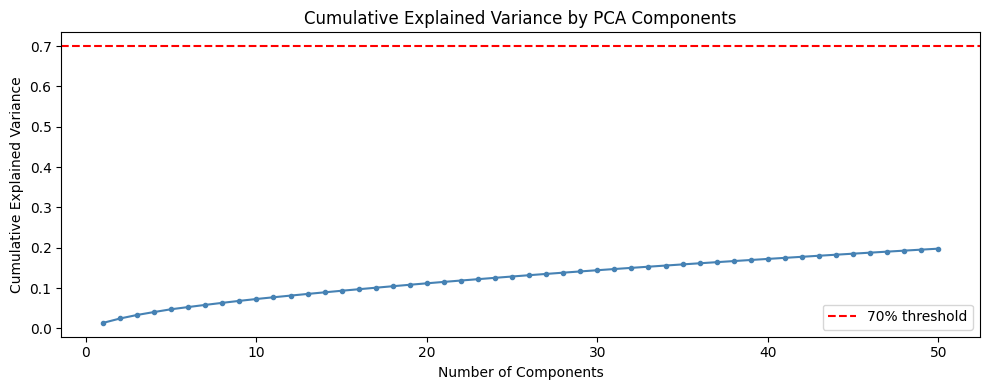


  Components needed to reach 70% variance: 1
  PC1 explains         : 1.4%
  PC2 explains         : 1.1%
  PC1+PC2 combined     : 2.5%


In [23]:
pca50        = PCA(n_components=50, random_state=42)
tfidf_dense  = tfidf_matrix.toarray()
pca50_result = pca50.fit_transform(tfidf_dense)

cumvar = np.cumsum(pca50.explained_variance_ratio_)
plt.figure(figsize=(10, 4))
plt.plot(range(1, 51), cumvar, marker='o', markersize=3, color='steelblue')
plt.axhline(0.70, color='red', linestyle='--', label='70% threshold')
plt.title('Cumulative Explained Variance by PCA Components')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.legend()
plt.tight_layout()
plt.show()

n70 = np.argmax(cumvar >= 0.70) + 1
print(f'\n  Components needed to reach 70% variance: {n70}')
print(f'  PC1 explains         : {pca50.explained_variance_ratio_[0]*100:.1f}%')
print(f'  PC2 explains         : {pca50.explained_variance_ratio_[1]*100:.1f}%')
print(f'  PC1+PC2 combined     : {cumvar[1]*100:.1f}%')

###2D Scatter Plot:

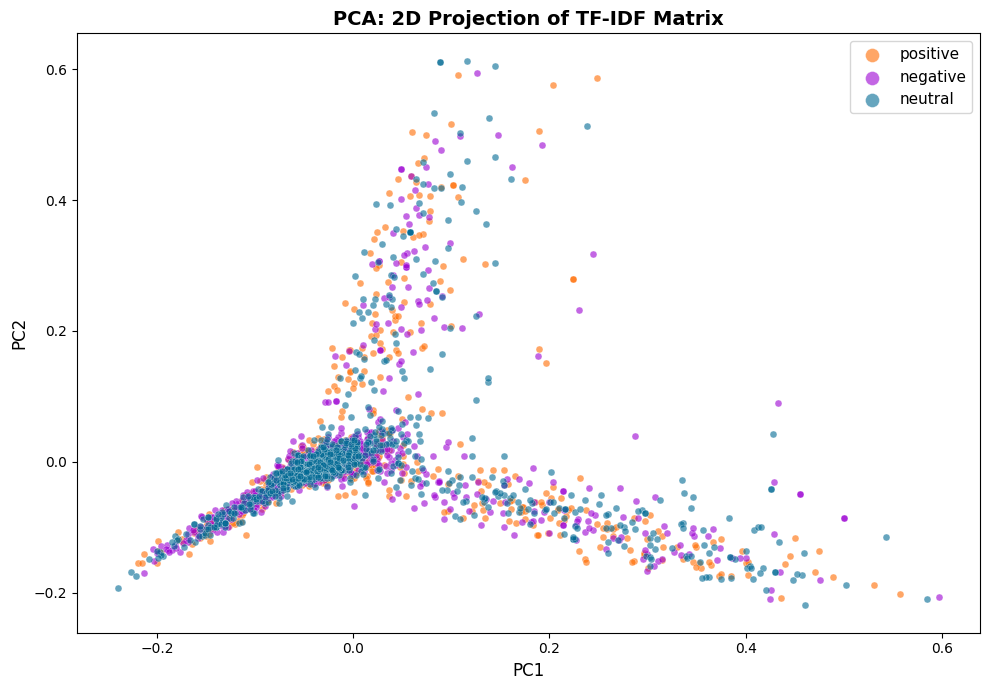

In [24]:
pca2        = PCA(n_components=2, random_state=42)
pca2_result = pca2.fit_transform(tfidf_dense)

df['pca1'] = pca2_result[:, 0]
df['pca2'] = pca2_result[:, 1]

plt.figure(figsize=(10, 7))

colors = {
    'positive': '#ff6b00',
    'negative': '#9b00d3',
    'neutral' : '#006994'
}

for label, color in colors.items():
    mask = df['sentiment'] == label
    plt.scatter(df.loc[mask, 'pca1'], df.loc[mask, 'pca2'],
                c=color,
                label=label,
                alpha=0.6,
                s=25,
                edgecolors='white',
                linewidths=0.3)

plt.title('PCA: 2D Projection of TF-IDF Matrix', fontsize=14, fontweight='bold')
plt.xlabel('PC1', fontsize=12)
plt.ylabel('PC2', fontsize=12)
plt.legend(fontsize=11, markerscale=2)
plt.tight_layout()
plt.show()


# TASK 12: Clustering with K-Means and DBSCAN


In [25]:
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm

In [26]:
X = pca50_result

k_values          = [2, 3, 4, 5]
inertias          = []
silhouette_scores = []

print("=" * 55)
print("K-Means Results on PCA-50")
print("=" * 55)

for k in k_values:
    km     = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X)
    inertias.append(km.inertia_)
    sil = silhouette_score(X, labels)
    silhouette_scores.append(sil)
    print(f"k={k} | Inertia: {km.inertia_:>12.2f} | Silhouette: {sil:.4f}")

K-Means Results on PCA-50
k=2 | Inertia:       543.35 | Silhouette: 0.1190
k=3 | Inertia:       517.46 | Silhouette: 0.1272
k=4 | Inertia:       497.09 | Silhouette: 0.1207
k=5 | Inertia:       484.98 | Silhouette: 0.0687


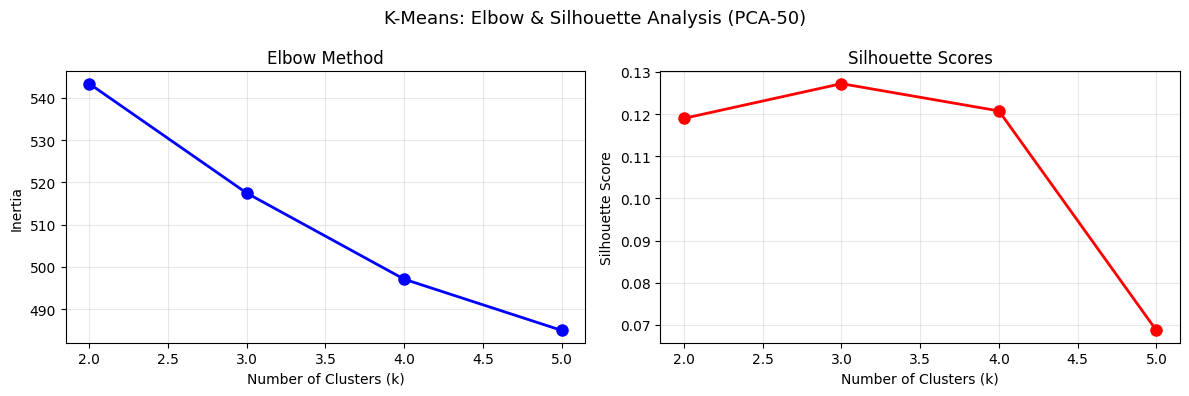


✅ Best k = 3  (Silhouette = 0.1272)


In [27]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(k_values, inertias, 'bo-', linewidth=2, markersize=8)
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Inertia')
ax1.set_title('Elbow Method')
ax1.grid(True, alpha=0.3)

ax2.plot(k_values, silhouette_scores, 'ro-', linewidth=2, markersize=8)
ax2.set_xlabel('Number of Clusters (k)')
ax2.set_ylabel('Silhouette Score')
ax2.set_title('Silhouette Scores')
ax2.grid(True, alpha=0.3)

plt.suptitle('K-Means: Elbow & Silhouette Analysis (PCA-50)', fontsize=13)
plt.tight_layout()
plt.show()

# Auto pick best k
best_k = k_values[silhouette_scores.index(max(silhouette_scores))]
print(f"\n✅ Best k = {best_k}  (Silhouette = {max(silhouette_scores):.4f})")

In [28]:
km_best        = KMeans(n_clusters=best_k, random_state=42, n_init=10)
km_best_labels = km_best.fit_predict(X)


centroids_tfidf = pca50.inverse_transform(km_best.cluster_centers_)

print(f"\nTop 10 words per cluster (k={best_k}):")
print("=" * 55)
for i, centroid in enumerate(centroids_tfidf):
    top10_idx   = centroid.argsort()[-10:][::-1]
    top10_words = [feature_names[j] for j in top10_idx]
    print(f"Cluster {i}: {top10_words}")


Top 10 words per cluster (k=3):
Cluster 0: ['coffee', 'cup', 'flavor', 'taste', 'like', 'good', 'roast', 'pod', 'strong', 'brew']
Cluster 1: ['taste', 'like', 'good', 'flavor', 'dog', 'make', 'love', 'great', 'try', 'eat']
Cluster 2: ['tea', 'taste', 'like', 'bag', 'green', 'flavor', 'good', 'drink', 'black', 'love']


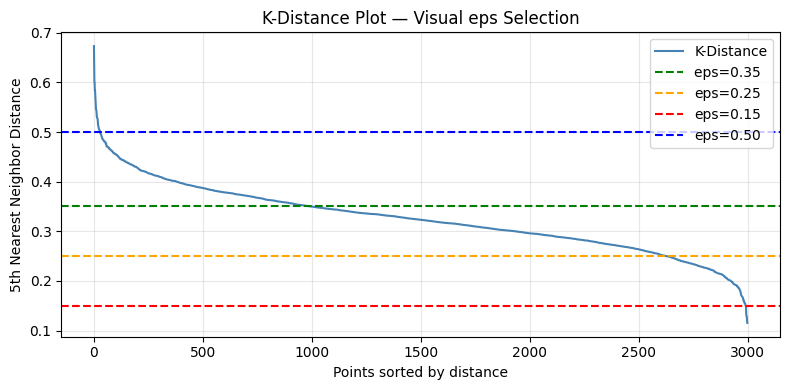

In [29]:
nbrs         = NearestNeighbors(n_neighbors=5).fit(X)
distances, _ = nbrs.kneighbors(X)
k_distances  = np.sort(distances[:, 4])[::-1]

plt.figure(figsize=(8, 4))
plt.plot(k_distances, linewidth=1.5, color='steelblue', label='K-Distance')
plt.axhline(y=0.35, color='green',  linestyle='--', label='eps=0.35 ')
plt.axhline(y=0.25, color='orange', linestyle='--', label='eps=0.25')
plt.axhline(y=0.15, color='red',    linestyle='--', label='eps=0.15')
plt.axhline(y=0.50, color='blue',   linestyle='--', label='eps=0.50')
plt.xlabel('Points sorted by distance')
plt.ylabel('5th Nearest Neighbor Distance')
plt.title('K-Distance Plot — Visual eps Selection')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [30]:
eps_values = [0.15, 0.25, 0.35, 0.50]
db_results = []

print("\n" + "=" * 55)
print("DBSCAN Results on PCA-50")
print("=" * 55)

for eps in eps_values:
    db         = DBSCAN(eps=eps, min_samples=5).fit(X)
    labels     = db.labels_
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise    = (labels == -1).sum()
    noise_pct  = n_noise / len(labels) * 100

    db_results.append({
        'eps'       : eps,
        'labels'    : labels,
        'n_clusters': n_clusters,
        'n_noise'   : n_noise,
        'noise_pct' : noise_pct
    })
    print(f"eps={eps:<5} | Clusters: {n_clusters:<4} | "
          f"Noise: {n_noise:<5} | Noise%: {noise_pct:.1f}%")

# From k-distance plot visual inspection — 0.35 is the elbow
best_eps       = 0.35
best_db        = next(r for r in db_results if r['eps'] == best_eps)
db_best_labels = best_db['labels']

print(f"\n✅ Best eps = {best_eps}  "
      f"(Clusters={best_db['n_clusters']}, "
      f"Noise={best_db['n_noise']}, "
      f"Noise%={best_db['noise_pct']:.1f}%)")


DBSCAN Results on PCA-50
eps=0.15  | Clusters: 1    | Noise: 2976  | Noise%: 99.2%
eps=0.25  | Clusters: 6    | Noise: 2369  | Noise%: 79.0%
eps=0.35  | Clusters: 3    | Noise: 552   | Noise%: 18.4%
eps=0.5   | Clusters: 1    | Noise: 10    | Noise%: 0.3%

✅ Best eps = 0.35  (Clusters=3, Noise=552, Noise%=18.4%)


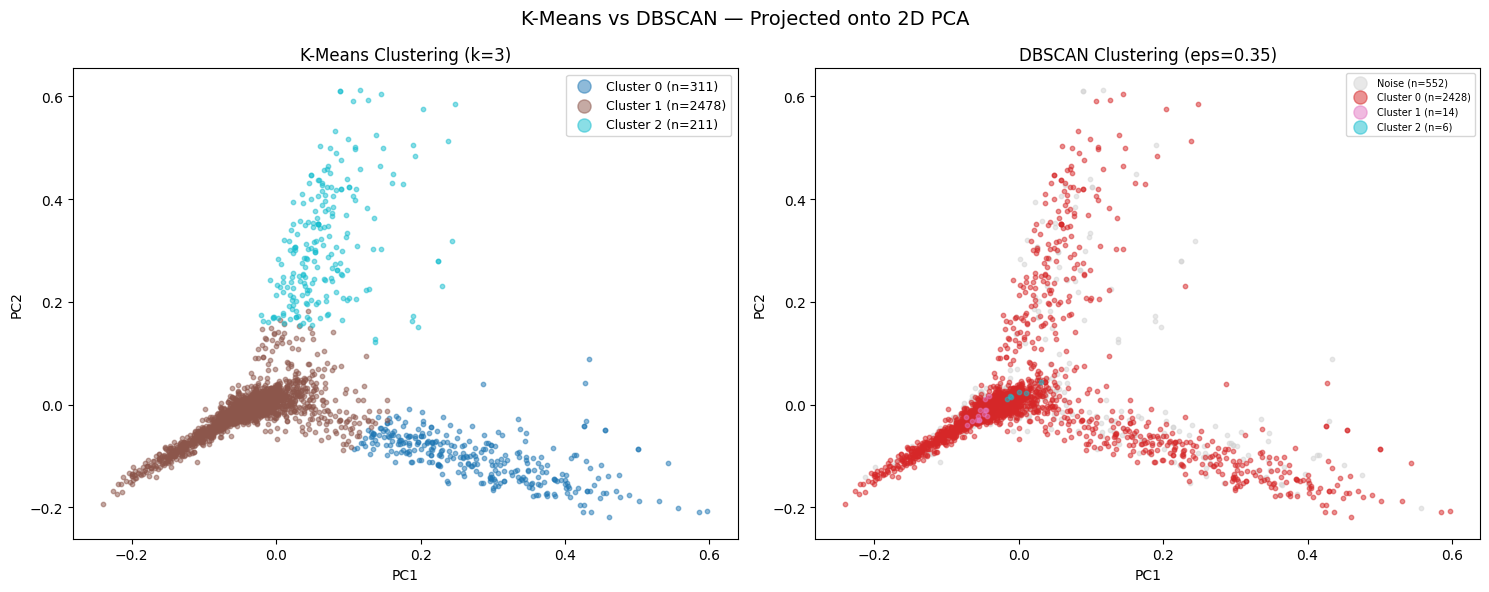

In [31]:
pca2d = PCA(n_components=2, random_state=42)
X_vis = pca2d.fit_transform(pca50_result)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# --- K-Means plot ---
colors_km = cm.tab10(np.linspace(0, 1, best_k))
for cluster in range(best_k):
    mask = km_best_labels == cluster
    ax1.scatter(X_vis[mask, 0], X_vis[mask, 1],
                label=f'Cluster {cluster} (n={mask.sum()})',
                alpha=0.5, s=10, color=colors_km[cluster])
ax1.set_title(f'K-Means Clustering (k={best_k})', fontsize=12)
ax1.set_xlabel('PC1')
ax1.set_ylabel('PC2')
ax1.legend(markerscale=3, fontsize=9)

# --- DBSCAN plot ---
unique_labels = sorted(set(db_best_labels))
colors_db     = cm.tab10(np.linspace(0, 1, max(len(unique_labels), 1)))

for idx, label in enumerate(unique_labels):
    mask  = db_best_labels == label
    name  = 'Noise' if label == -1 else f'Cluster {label}'
    color = 'lightgray' if label == -1 else colors_db[idx]
    ax2.scatter(X_vis[mask, 0], X_vis[mask, 1],
                label=f'{name} (n={mask.sum()})',
                alpha=0.5, s=10, color=color)
ax2.set_title(f'DBSCAN Clustering (eps={best_eps})', fontsize=12)
ax2.set_xlabel('PC1')
ax2.set_ylabel('PC2')
ax2.legend(markerscale=3, fontsize=7)

plt.suptitle('K-Means vs DBSCAN — Projected onto 2D PCA', fontsize=14)
plt.tight_layout()
plt.show()

# Task 13: VADER Sentiment Analysis

 VADER Predicted Sentiment Distribution:
vader_label
positive    2267
negative     636
neutral       97
Name: count, dtype: int64

Percentage breakdown:
vader_label
positive    75.6%
negative    21.2%
neutral      3.2%
Name: proportion, dtype: object


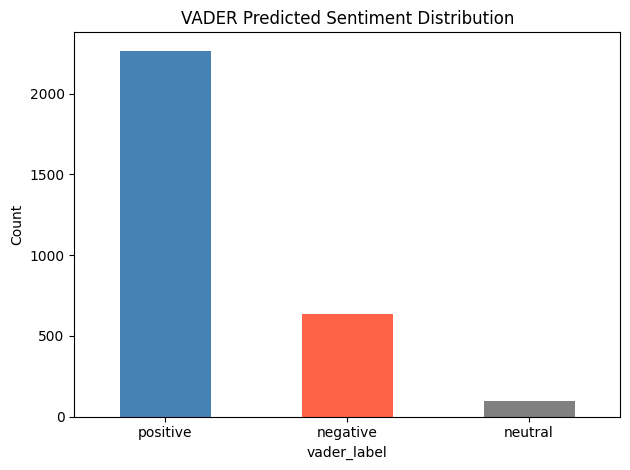

In [32]:

sia = SentimentIntensityAnalyzer()

def vader_label(text):
    score = sia.polarity_scores(str(text))
    compound = score['compound']
    if compound >= 0.05:
        return 'positive'
    elif compound <= -0.05:
        return 'negative'
    else:
        return 'neutral'

df['vader_label'] = df['review'].apply(vader_label)
df['vader_score'] = df['review'].apply(lambda x: sia.polarity_scores(str(x))['compound'])

#  Sentiment Distribution (all 3 VADER labels)
print(' VADER Predicted Sentiment Distribution:')
print(df['vader_label'].value_counts())
print(f'\nPercentage breakdown:')
print(df['vader_label'].value_counts(normalize=True).mul(100).round(1).astype(str) + '%')

df['vader_label'].value_counts().plot(kind='bar', color=['steelblue','tomato','gray'],
                                       title='VADER Predicted Sentiment Distribution', rot=0)
plt.ylabel('Count')
plt.tight_layout()
plt.show()

In [33]:
#  Polarity Score Statistics
print('\n Polarity Score Statistics:')

print(f"  Overall    — Mean: {df['vader_score'].mean():.4f}, Std: {df['vader_score'].std():.4f}")

# Per TRUE label (all 3 ground truth classes)
for label in ['positive', 'negative', 'neutral']:
    sub = df[df['sentiment'] == label]['vader_score']
    print(f"  {label.capitalize():<10} — Mean: {sub.mean():.4f}, Std: {sub.std():.4f}")


 Polarity Score Statistics:
  Overall    — Mean: 0.4497, Std: 0.5781
  Positive   — Mean: 0.7622, Std: 0.3285
  Negative   — Mean: 0.1048, Std: 0.6260
  Neutral    — Mean: 0.4821, Std: 0.5345



 VADER Accuracy (vs ground truth): 46.77%

Classification Report:
              precision    recall  f1-score   support

    negative       0.65      0.41      0.51      1000
     neutral       0.43      0.04      0.08      1000
    positive       0.42      0.95      0.58      1000

    accuracy                           0.47      3000
   macro avg       0.50      0.47      0.39      3000
weighted avg       0.50      0.47      0.39      3000



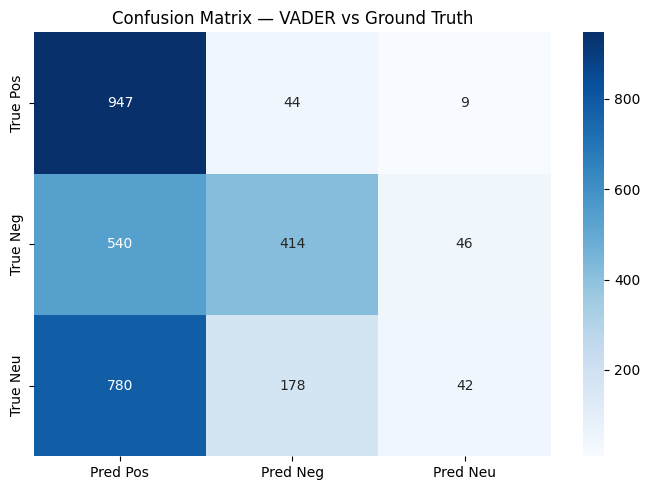

In [34]:
#  Evaluation against ground-truth labels

true_labels = df['sentiment']
vader_preds = df['vader_label']

acc = accuracy_score(true_labels, vader_preds)
print(f'\n VADER Accuracy (vs ground truth): {acc*100:.2f}%')
print('\nClassification Report:')
print(classification_report(true_labels, vader_preds))

# Confusion matrix
cm = confusion_matrix(true_labels, vader_preds, labels=['positive','negative','neutral'])
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pred Pos','Pred Neg','Pred Neu'],
            yticklabels=['True Pos','True Neg','True Neu'])
plt.title('Confusion Matrix — VADER vs Ground Truth')
plt.tight_layout()
plt.show()

In [35]:
#  Show 2 misclassified examples
misclassified = df[true_labels != vader_preds]
print(f'\nTotal misclassified: {len(misclassified)} reviews')
print('\n 2 Misclassified Examples:')
print('='*70)
for i, row in misclassified.sample(2, random_state=7).iterrows():
    print(f"True label   : {row['sentiment']}")
    print(f"VADER label  : {row['vader_label']}")
    print(f"VADER score  : {row['vader_score']:.4f}")
    print(f"Review       : {str(row['review'])[:300]}...")
    print('-'*70)


Total misclassified: 1597 reviews

 2 Misclassified Examples:
True label   : neutral
VADER label  : positive
VADER score  : 0.8760
Review       : Although I got them for a great price I won't be ordering this again from Amazon. I got 4 boxes of honey bunches of oats with strawberries but I'm guessing due to so much travel, by the time they got to me, the cereal was in pretty small pieces. All flakes had been broken down, and the granola wasn'...
----------------------------------------------------------------------
True label   : neutral
VADER label  : positive
VADER score  : 0.9833
Review       : The Kind bars are just too sweet for me. But I love the fruit and nut ratio and crunch with every bite. I was hoping this would work because it's gluten and wheat free, all natural, has a low glycemic index and a decent amount of fiber, no trans fats and the price is great on Amazon and with "subscr...
----------------------------------------------------------------------
